# From $n(z)$ to cosmology: a 3×2pt analysis you can break

We build a small but complete 3×2pt analysis with **one lens bin and one source bin** and four real-space
two-point functions:

| | measures | scales as |
|---|---|---|
| $w(\theta)$ | lens–lens clustering | $b^2 P$ |
| $\gamma_t(\theta)$ | galaxy–galaxy lensing | $b\,\Omega_m P$ |
| $\xi_\pm(\theta)$ | cosmic shear | $\Omega_m^2 P$ |

0. **Setup:** survey, $n(z)$ and the model.
1. **The data vector and its covariance.**
2. **Forecasts:** what each probe constrains, using DALI posteriors.
3. **An unmodelled photo-$z$ or shear-calibration error:** where the posterior lands when the model is wrong.
4. **Unmodelled intrinsic alignments and baryons.**

`bias_explorer.html` (this folder) is an interactive companion to parts 3–4: open it in a browser.
`cat2cosmo_tools.py` holds plotting and numerical helpers; the physics is all in this notebook.
Runtime: about 2 minutes (one model evaluation takes ~0.4 s).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyccl as ccl
from scipy.integrate import trapezoid
from scipy.linalg import solve_triangular
from scipy.optimize import least_squares
from derivkit import ForecastKit

import cat2cosmo_tools as tools
from cat2cosmo_tools import CORAL, BLUE, MAGENTA, GOLD, GRAY
tools.set_style()

## 0. The survey and the model

A roughly Stage-III survey: $f_{\rm sky}=0.1$ (about 4000 deg²), $n_{\rm src}=5$ arcmin⁻², $\sigma_e=0.26$ per
component, $n_{\rm lens}=0.2$ arcmin⁻². The lens bin is a narrow Gaussian at $z=0.4$; the source bin is a broad
$z^2 e^{-(z/0.4)^{1.4}}$. Both are read from disk, so you can swap in your own.

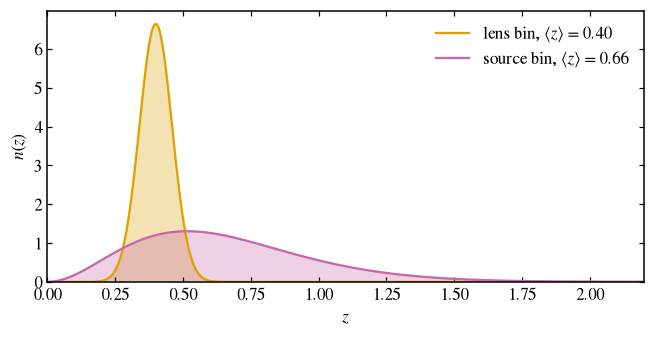

In [2]:
survey = np.load('data/survey.npz')
Z, NZ_LENS, NZ_SRC = survey['z'], survey['nz_lens'], survey['nz_src']
THETA, THETA_EDGES = survey['theta'], survey['theta_edges']     # arcmin
NTHETA = len(THETA)                                             # 20 angular bins per probe
PROBES = ['w', 'gt', 'xip', 'xim']
saved = np.load('data/cov_gaussian.npz')
COV, D_SAVED = saved['cov'], saved['data_fid']                  # 80 × 80 covariance, fiducial data vector

fig, ax = plt.subplots(figsize=(7, 3.2))
for nz, col, name in [(NZ_LENS, GOLD, 'lens'), (NZ_SRC, MAGENTA, 'source')]:
    ax.fill_between(Z, nz, color=col, alpha=0.3, lw=0)
    ax.plot(Z, nz, color=col, label=rf'{name} bin, $\langle z\rangle = {trapezoid(Z * nz, Z):.2f}$')
ax.set(xlim=(0, 2.2), ylim=(0, None), xlabel='$z$', ylabel='$n(z)$')
ax.legend(); plt.show()

**The model.** $\Omega_m$ and $S_8 \equiv \sigma_8\sqrt{\Omega_m/0.3}$ are free; $\Omega_b$, $h$ and $n_s$ are fixed.
The matter power spectrum is Eisenstein–Hu plus halofit, so no Boltzmann code is needed. Every parameter you
don't pass to the model takes its `FIDUCIAL` value.

In [3]:
FIXED = dict(Omega_b=0.049, h=0.677, n_s=0.965)
FIDUCIAL = dict(Om=0.31, S8=0.80, b=1.6,           # cosmology + lens galaxy bias
                A_IA=0.0, eta_IA=0.0,               # NLA intrinsic alignments
                dz_s=0.0, dz_l=0.0, m=0.0,          # photo-z shifts, shear calibration
                A_bar=0.0, logk_bar=1.0)            # baryon dip: depth, log10(k / [h/Mpc])

ELL = np.unique(np.geomspace(2, 1e5, 160).astype(int)).astype(float)
THETA_SUB, W_SUB = tools.sub_bins(THETA_EDGES)      # points inside each angular bin, for bin averaging


def get_cosmo(Om, S8):
    sigma8 = S8 / np.sqrt(Om / 0.3)
    return ccl.Cosmology(Omega_c=Om - FIXED['Omega_b'], Omega_b=FIXED['Omega_b'], h=FIXED['h'],
                         n_s=FIXED['n_s'], sigma8=sigma8,
                         transfer_function='eisenstein_hu', matter_power_spectrum='halofit')

Three ways the real Universe can differ from our model, each a simple ingredient:

- **Baryons** suppress $P(k)$ on small scales; here a parametric dip of depth $A$ at $k_d$.
- **Photo-$z$ errors**: the true $n(z)$ is the assumed one shifted by $\Delta z$.
- **Intrinsic alignments** (next cell): the NLA model, $A(z) = A_{\rm IA}[(1+z)/1.62]^{\eta_{\rm IA}}$.

In [4]:
def baryon_suppression(k_h, A_bar, logk_bar, width=0.45):
    """P_bar / P_dmo = 1 - A exp[-log10^2(k/k_d) / (2 width^2)], k in h/Mpc."""
    return 1.0 - A_bar * np.exp(-0.5 * ((np.log10(k_h) - logk_bar) / width) ** 2)


def shift_nz(nz, dz):
    """Photo-z error: the true n(z) is the assumed one shifted by dz."""
    out = np.interp(Z - dz, Z, nz, left=0.0, right=0.0)
    return out / trapezoid(out, Z)


def matter_pk(cosmo, A_bar, logk_bar):
    """Halofit P(k, a) times the baryon feature, as a CCL Pk2D."""
    a = np.linspace(1 / 4.5, 1.0, 48)
    k = np.geomspace(1e-4, 1e2, 256)                                       # 1/Mpc
    pk = np.array([ccl.nonlin_matter_power(cosmo, k, ai) for ai in a])
    pk *= baryon_suppression(k / FIXED['h'], A_bar, logk_bar)
    return ccl.Pk2D(a_arr=a, lk_arr=np.log(k), pk_arr=np.log(pk), is_logp=True)

The data vector: Limber $C_\ell$ for $gg$, $g\kappa$ and $\kappa\kappa$, Hankel-transformed to $w$, $\gamma_t$, $\xi_\pm$
and averaged over each angular bin. Shear calibration multiplies $\gamma_t$ by $(1+m)$ and $\xi_\pm$ by $(1+m)^2$.

In [5]:
def data_vector(params):
    """Bin-averaged [w, gamma_t, xi+, xi-] for a dict of parameters (missing ones take FIDUCIAL values)."""
    p = {**FIDUCIAL, **params}
    cosmo = get_cosmo(p['Om'], p['S8'])
    pk = matter_pk(cosmo, p['A_bar'], p['logk_bar'])
    lens = ccl.NumberCountsTracer(cosmo, has_rsd=False, dndz=(Z, shift_nz(NZ_LENS, p['dz_l'])),
                                  bias=(Z, np.full_like(Z, p['b'])))
    src = ccl.WeakLensingTracer(cosmo, dndz=(Z, shift_nz(NZ_SRC, p['dz_s'])),
                                ia_bias=(Z, p['A_IA'] * ((1 + Z) / 1.62) ** p['eta_IA']))
    cl = {'gg': ccl.angular_cl(cosmo, lens, lens, ELL, p_of_k_a=pk),
          'gk': ccl.angular_cl(cosmo, lens, src, ELL, p_of_k_a=pk),
          'kk': ccl.angular_cl(cosmo, src, src, ELL, p_of_k_a=pk)}
    spectra = {'w': ('gg', 'NN', 1), 'gt': ('gk', 'NG', 1 + p['m']),
               'xip': ('kk', 'GG+', (1 + p['m']) ** 2), 'xim': ('kk', 'GG-', (1 + p['m']) ** 2)}
    out = []
    for probe in PROBES:
        key, kind, shear_calib = spectra[probe]
        xi = ccl.correlation(cosmo, ell=ELL, C_ell=cl[key], theta=THETA_SUB.ravel() / 60, type=kind)
        out.append(shear_calib * (xi.reshape(THETA_SUB.shape) * W_SUB).sum(axis=1))
    return np.concatenate(out)

In [6]:
D_FID = data_vector({})
print('matches the saved fiducial data vector:', np.allclose(D_FID, D_SAVED))

matches the saved fiducial data vector: True


## 1. The data vector and its covariance

The covariance in `data/cov_gaussian.npz` is **Gaussian**: cosmic variance plus shape and shot noise, including
all cross-probe terms (no super-sample or non-Gaussian terms). For correlation functions of fields $A,B$ and $C,D$:

$$
\mathrm{Cov}\big[\xi^{AB}(\theta_i),\,\xi^{CD}(\theta_j)\big] = \frac{1}{\Omega_s}\int\frac{\ell\,d\ell}{2\pi}\;
\bar J_{n}(\ell\theta_i)\,\bar J_{m}(\ell\theta_j)\,\Big[\tilde C^{AC}_\ell \tilde C^{BD}_\ell + \tilde C^{AD}_\ell \tilde C^{BC}_\ell\Big],
\qquad \tilde C_\ell = C_\ell + N_\ell ,
$$

with bin-averaged Bessel functions $\bar J_n$ ($J_0$ for $w$, $\xi_+$; $J_2$ for $\gamma_t$; $J_4$ for $\xi_-$) and
noise $N^{\kappa\kappa} = \sigma_e^2/n_{\rm src}$, $N^{gg} = 1/n_{\rm lens}$.

**Scale cuts.** Our galaxy bias is *linear*, which only holds on large scales, so we keep $w$ above 8 Mpc/$h$
and $\gamma_t$ above 6 Mpc/$h$ (converted to angles at the lens redshift). Cosmic shear keeps all scales.

In [7]:
cosmo_fid = get_cosmo(FIDUCIAL['Om'], FIDUCIAL['S8'])
CHI_LENS = ccl.comoving_radial_distance(cosmo_fid, 1 / 1.4) * FIXED['h']    # Mpc/h, at z = 0.4

def make_mask(probes=PROBES, R_w=8, R_gt=6, theta_xi=0):
    # keep `probes`; drop w below R_w and gamma_t below R_gt [Mpc/h], xi+- below theta_xi [arcmin]
    to_arcmin = lambda R: np.degrees(R / CHI_LENS) * 60
    tmin = {'w': to_arcmin(R_w), 'gt': to_arcmin(R_gt), 'xip': theta_xi, 'xim': theta_xi}
    return np.concatenate([(THETA >= tmin[p]) & (p in probes) for p in PROBES])

MASK = make_mask()
print(f'{MASK.sum()} of {MASK.size} data points kept')

61 of 80 data points kept


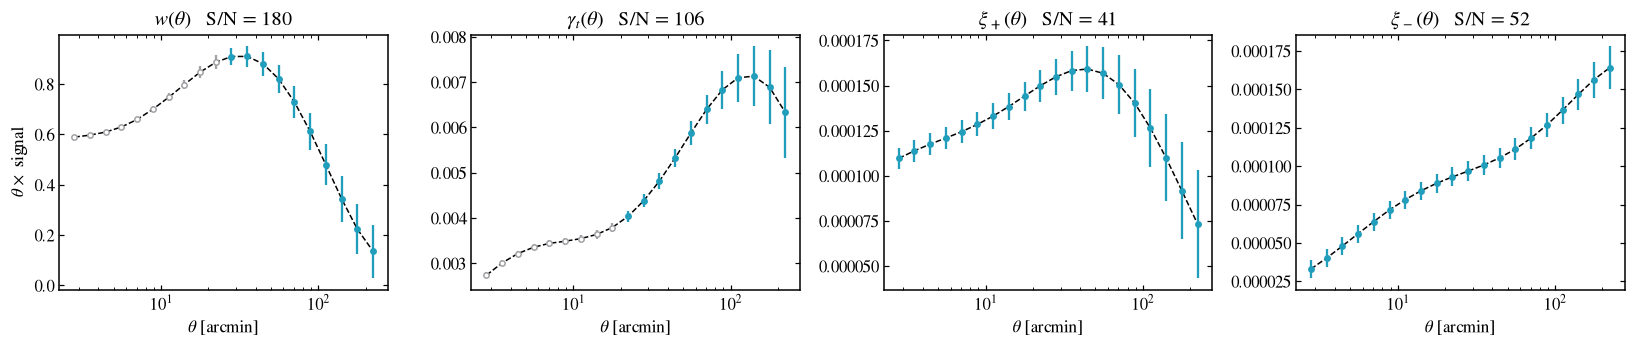

In [8]:
SIG = np.sqrt(np.diag(COV))
titles = {'w': r'$w(\theta)$', 'gt': r'$\gamma_t(\theta)$', 'xip': r'$\xi_+(\theta)$', 'xim': r'$\xi_-(\theta)$'}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
for k, (ax, p) in enumerate(zip(axes, PROBES)):
    s = slice(NTHETA * k, NTHETA * (k + 1))
    y, err, keep = THETA * D_FID[s], THETA * SIG[s], MASK[s]
    snr = np.sqrt(D_FID[s] @ np.linalg.solve(COV[s, s], D_FID[s]))
    ax.plot(THETA, y, 'k--', lw=1)
    ax.errorbar(THETA[keep], y[keep], err[keep], fmt='o', ms=3.5, color=BLUE)
    ax.errorbar(THETA[~keep], y[~keep], err[~keep], fmt='o', ms=3.5, color=GRAY, mfc='w')    # removed by cuts
    ax.set(xscale='log', xlabel=r'$\theta$ [arcmin]', title=f'{titles[p]}   S/N = {snr:.0f}')
axes[0].set_ylabel(r'$\theta \times$ signal')
plt.tight_layout(); plt.show()

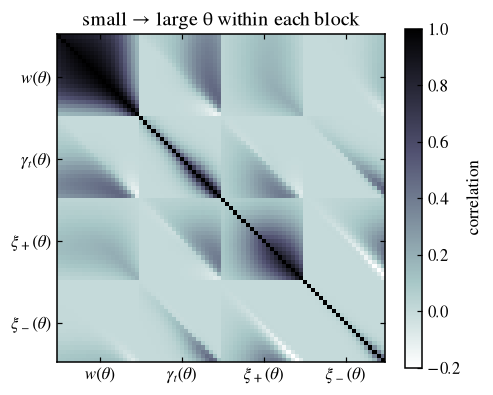

In [9]:
fig, ax = plt.subplots(figsize=(4.8, 4))
im = ax.imshow(COV / np.outer(SIG, SIG), cmap='bone_r', vmin=-0.2, vmax=1)
centres = NTHETA * np.arange(4) + NTHETA // 2
ax.set_xticks(centres, list(titles.values())); ax.set_yticks(centres, list(titles.values()))
plt.colorbar(im, label='correlation'); ax.set_title('small → large θ within each block'); plt.show()

- Neighbouring large-$\theta$ bins are strongly correlated: one cosmic-variance mode spans many bins.
- Small-$\theta$ bins are nearly independent because shape noise dominates there.
- $\gamma_t$ and $\xi_\pm$ are correlated because they share the same source shapes and matter field.

## 2. Forecasts with DALI

The usual quick forecast is the **Fisher matrix**, $F = J^T C^{-1} J$ with $J = \partial\mathbf d/\partial\theta$. It
assumes the model is *linear* in the parameters, so every posterior comes out as an ellipse.

**DALI** keeps the next order. Expand the model to second order,
$\mathbf d(\theta_0+\delta) \approx \mathbf d_0 + J\delta + \tfrac12 H\delta\delta$ with $H = \partial^2\mathbf d/\partial\theta\,\partial\theta$,
and use the *exact* $\chi^2$ of that expanded model:

$$\chi^2(\delta) = \big|\Delta\mathbf d - J\delta - \tfrac12 H\delta\delta\big|^2_{C}
= \delta^T F\delta + D_1[\delta^3] + \tfrac14 D_2[\delta^4] + (\text{terms with } \Delta\mathbf d),$$

where $D_1 = H^T C^{-1} J$, $D_2 = H^T C^{-1} H$, and $\Delta\mathbf d$ is how far the data sit from the fiducial
model. It is zero for now; in parts 3–4 it carries the systematic. The posterior can now bend into bananas and
become skewed, while costing no more than a few tensor contractions.

[derivkit](https://docs.derivkit.org) computes $J$ and $H$ for us (about 40 model calls). We vary
$(\Omega_m, S_8, b)$ with weak Gaussian priors and flat ranges.

In [10]:
NAMES3 = ['Om', 'S8', 'b']
THETA0_3 = np.array([FIDUCIAL[n] for n in NAMES3])          # the truth: (0.31, 0.80, 1.6)
S8_TRUE = THETA0_3[1]
PRIOR_SIG3 = np.array([0.3, 0.5, 1.0])                      # weak Gaussian priors, centred on the truth
PRIOR3 = np.diag(1 / PRIOR_SIG3 ** 2)
BOUNDS3 = [(0.1, 0.6), (0.5, 1.1), (0.5, 3.5)]              # flat prior ranges

def model3(theta):
    return data_vector(dict(zip(NAMES3, theta)))

fk3 = ForecastKit(function=model3, theta0=THETA0_3, cov=COV)
dali, derivs = fk3.dali(method='finite', stepsize=4e-3, forecast_order=2, return_derivatives=True)
J3, H3 = derivs[1], derivs[2]                               # shapes (80, 3) and (80, 3, 3)

With only three parameters we don't need an MCMC: `tools.grid_posterior` evaluates the DALI posterior on a grid
in $(\Omega_m, S_8)$ and integrates over $b$ numerically, giving exact marginals in a fraction of a second. Each
probe combination simply uses a different subset (`mask`) of the data vector.

In [11]:
def posterior(mask, dd=None):
    # DALI posterior of (Om, S8, b) from the data points in `mask`; dd = shift of the data (None: data at truth)
    T = tools.dali_tensors(J3, H3, COV, mask, dd)
    return tools.grid_posterior(T, THETA0_3, PRIOR3, BOUNDS3)

T = tools.dali_tensors(J3, H3, COV, np.ones(80, bool))
print('our tensors match derivkit:', all(np.allclose(a, b) for a, b in zip([T['F'], T['D1'], T['D2']], [*dali[1], *dali[2]])))

our tensors match derivkit: True


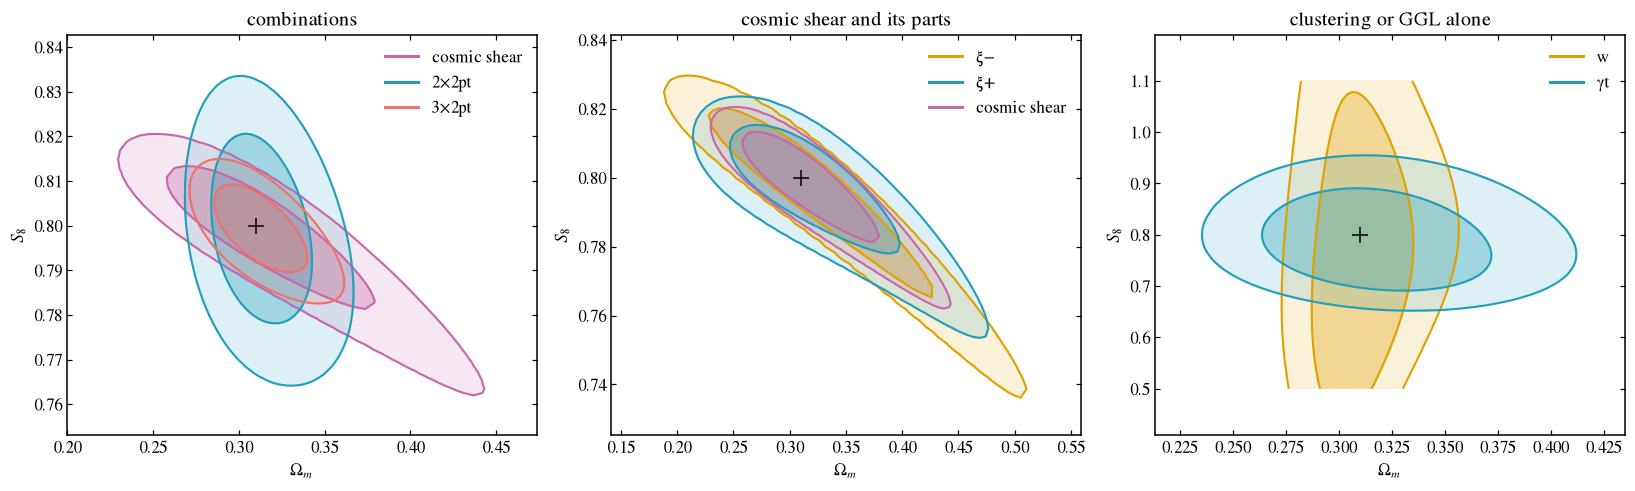

In [12]:
COMBOS = {'3×2pt': ['w', 'gt', 'xip', 'xim'], '2×2pt': ['w', 'gt'], 'cosmic shear': ['xip', 'xim'],
          'w': ['w'], 'γt': ['gt'], 'ξ+': ['xip'], 'ξ−': ['xim']}
COLOR = {'3×2pt': CORAL, '2×2pt': BLUE, 'cosmic shear': MAGENTA, 'w': GOLD, 'γt': BLUE, 'ξ+': BLUE, 'ξ−': GOLD}
POST = {name: posterior(make_mask(probes)) for name, probes in COMBOS.items()}

panels = {'combinations': ['cosmic shear', '2×2pt', '3×2pt'],
          'cosmic shear and its parts': ['ξ−', 'ξ+', 'cosmic shear'],
          'clustering or GGL alone': ['w', 'γt']}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
for ax, (title, names) in zip(axes, panels.items()):
    tools.plot_posteriors(ax, [(POST[n], COLOR[n], n) for n in names], THETA0_3, title=title)
plt.tight_layout(); plt.show()

In [13]:
print('                σ(S8)   Fisher σ(S8)   (S8 mean − truth)/σ')
for name, R in POST.items():
    print(f"{name:12s} {R['sd'][1]:9.4f} {R['fisher_sd'][1]:12.4f} {(R['mean'][1] - S8_TRUE) / R['sd'][1]:+17.2f}")

                σ(S8)   Fisher σ(S8)   (S8 mean − truth)/σ
3×2pt           0.0066       0.0064             -0.16
2×2pt           0.0141       0.0139             -0.11
cosmic shear    0.0120       0.0098             -0.31
w               0.1554       0.3465             -0.12
γt              0.0632       0.0720             -0.11
ξ+              0.0139       0.0111             -0.35
ξ−              0.0192       0.0164             -0.37


**What to notice:**

- **3×2pt and 2×2pt** are so informative that the model is nearly linear across the posterior: DALI and Fisher
  errors agree to a few percent.
- **Cosmic shear alone** follows the curved $\sigma_8$–$\Omega_m$ degeneracy. Its contour is a banana, its error
  is ~20% larger than Fisher predicts, and the $S_8$ mean sits ~$0.3\sigma$ below the truth even though the data
  are perfect: the marginal of a skewed posterior is not centred on its peak.
- **$w$ alone** measures only $b\,\sigma_8$; its contour runs into the flat prior on $S_8$.
- Physically: shear measures roughly $S_8$; 2×2pt pins down $b$ ($w \propto b^2\sigma_8^2$,
  $\gamma_t \propto b\,\Omega_m\sigma_8^2$); 3×2pt breaks the remaining degeneracies (compare slide 028).

**Sanity check.** The grid should agree with an MCMC on the same DALI posterior, run with derivkit's `emcee`
wrapper. The Gaussian prior is centred on the truth, so it enters as a prior Fisher matrix added to $F$.

In [14]:
T = tools.dali_tensors(J3, H3, COV, make_mask(COMBOS['cosmic shear']))
chain = fk3.getdist_dali_emcee(dali={1: (T['F'] + PRIOR3,), 2: (T['D1'], T['D2'])}, names=NAMES3, labels=NAMES3,
                               prior_bounds=BOUNDS3, n_steps=4000, burn=1000, thin=4, seed=3)
print('grid:  mean', np.round(POST['cosmic shear']['mean'], 4), '  σ', np.round(POST['cosmic shear']['sd'], 4))
print('MCMC:  mean', np.round(chain.getMeans()[:3], 4), '  σ', np.round(np.sqrt(np.diag(chain.getCov()))[:3], 4))

Removed no burn in
grid:  mean [0.3227 0.7962 1.7821]   σ [0.0439 0.012  0.7287]
MCMC:  mean [0.3226 0.7964 1.7625]   σ [0.0433 0.0119 0.7261]


## 3. A photo-$z$ error that the analysis does not know about

Suppose the true sources sit at $z + \Delta z_s$, but we analyse with the nominal $n(z)$. The data move by
$\Delta\mathbf d$ and the model absorbs what it can by shifting the parameters. The DALI posterior with
$\Delta\mathbf d \neq 0$ tells us where the best fit lands and what the analyst would report. (The data are
noiseless, so this is the systematic shift alone.)

We quote shifts as $(\text{best fit} - \text{truth})/\sigma$.

In [15]:
def shift_in_sigma(R, i=1):
    # (best fit - truth) / sigma, for parameter i (default: S8)
    return (R['map'][i] - THETA0_3[i]) / R['sd'][i]

R = posterior(MASK, data_vector({'dz_s': 0.02}) - D_FID)
print(f"best fit (Ωm, S8, b) = {np.round(R['map'], 3)}   ->   ΔS8 = {shift_in_sigma(R):+.1f}σ")
print(f"χ² at the best fit = {R['chi2_data']:.2f} for {MASK.sum()} data points")

best fit (Ωm, S8, b) = [0.312 0.819 1.572]   ->   ΔS8 = +2.9σ
χ² at the best fit = 0.54 for 61 data points


A $\Delta z_s = 0.02$ error moves $S_8$ by about $3\sigma$, yet the best fit's $\chi^2$ is tiny: the wrong model
fits the data perfectly well. **Goodness of fit will not warn you**, which is why photo-$z$ calibration is a
central problem in lensing cosmology.

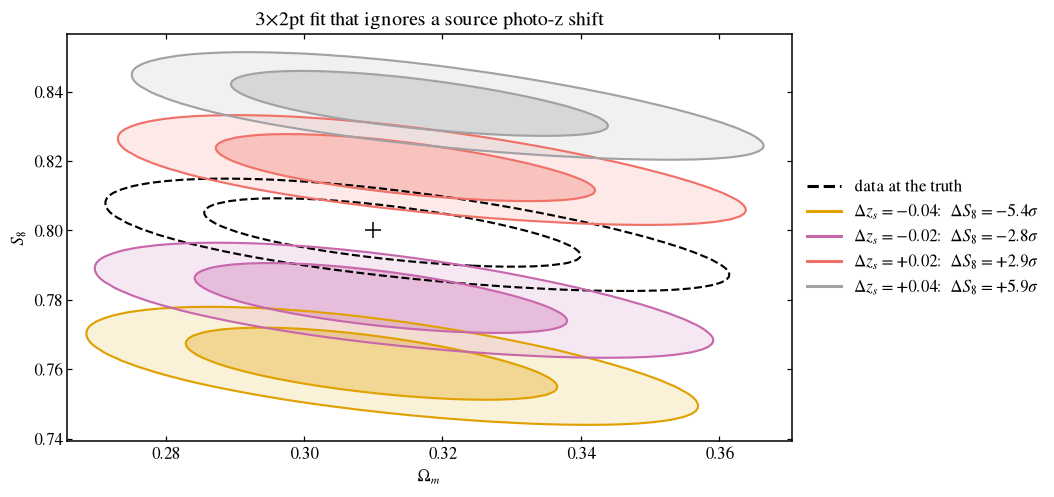

In [16]:
DZ_CASES = {-0.04: GOLD, -0.02: MAGENTA, 0.02: CORAL, 0.04: GRAY}
fits = {dz: posterior(MASK, data_vector({'dz_s': dz}) - D_FID) for dz in DZ_CASES}

fig, ax = plt.subplots(figsize=(8.5, 4.8))
entries = [(R, DZ_CASES[dz], rf'$\Delta z_s = {dz:+.2f}$:  $\Delta S_8 = {shift_in_sigma(R):+.1f}\sigma$')
           for dz, R in fits.items()]
tools.plot_posteriors(ax, entries, THETA0_3, reference=POST['3×2pt'], legend='right', pad=0.05,
                      title='3×2pt fit that ignores a source photo-z shift')
plt.show()

Which probes care about which systematic? The same shift for three systematics and three probe combinations:

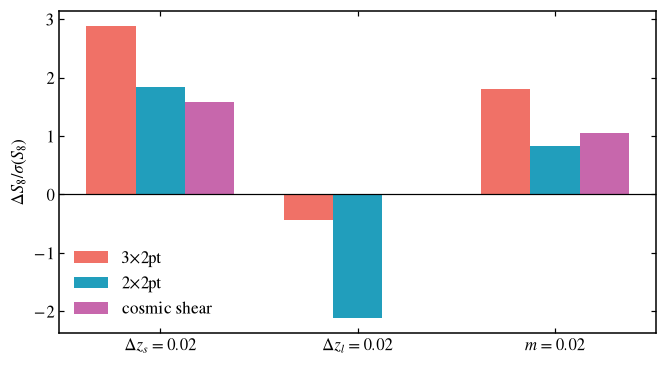

In [17]:
SYSTEMATICS = {r'$\Delta z_s = 0.02$': {'dz_s': 0.02}, r'$\Delta z_l = 0.02$': {'dz_l': 0.02}, r'$m = 0.02$': {'m': 0.02}}
DD = {k: data_vector(v) - D_FID for k, v in SYSTEMATICS.items()}

fig, ax = plt.subplots(figsize=(7, 3.8))
for j, name in enumerate(['3×2pt', '2×2pt', 'cosmic shear']):
    shifts = [shift_in_sigma(posterior(make_mask(COMBOS[name]), dd)) for dd in DD.values()]
    ax.bar(np.arange(3) + 0.25 * (j - 1), shifts, 0.25, color=COLOR[name], label=name)
ax.axhline(0, color='k', lw=0.8)
ax.set_xticks(range(3), list(SYSTEMATICS)); ax.set_ylabel(r'$\Delta S_8/\sigma(S_8)$'); ax.legend(); plt.show()

**How good is DALI here?** The right answer is the best fit of the *full* CCL model, found by minimising $\chi^2$
directly (20–40 model calls per fit). We compare it with DALI and with the textbook linear **Fisher bias**,
$\delta\theta = F^{-1}J^T C^{-1}\Delta\mathbf d$, which is what you get if you drop $H$.

In [18]:
L = np.linalg.cholesky(COV[np.ix_(MASK, MASK)])

def exact_best_fit(d_obs, start):
    def residuals(theta):          # whitened data residuals, plus the Gaussian priors
        r = solve_triangular(L, (d_obs - model3(theta))[MASK], lower=True)
        return np.concatenate([r, (theta - THETA0_3) / PRIOR_SIG3])
    return least_squares(residuals, start, x_scale=[0.01, 0.01, 0.05], diff_step=1e-3).x

print(f"{'shift in S8':12s} {'linear Fisher':>14s} {'DALI':>8s} {'exact':>8s}")
for dz in [0.01, 0.02, 0.05, 0.10]:
    d_obs = data_vector({'dz_s': dz})
    R = posterior(MASK, d_obs - D_FID)
    exact = exact_best_fit(d_obs, start=R['map'])
    print(f"Δz_s = {dz:.2f}  {R['lin'][1] - S8_TRUE:+14.4f} {R['map'][1] - S8_TRUE:+8.4f} {exact[1] - S8_TRUE:+8.4f}")

shift in S8   linear Fisher     DALI    exact


Δz_s = 0.01         +0.0095  +0.0094  +0.0094


Δz_s = 0.02         +0.0191  +0.0187  +0.0187


Δz_s = 0.05         +0.0486  +0.0464  +0.0463


Δz_s = 0.10         +0.1001  +0.0914  +0.0912


For small errors all three agree. At $\Delta z_s = 0.1$ the linear Fisher bias is ~10% off, while DALI still
tracks the exact answer to better than 1%. (For $\Omega_m$, which is less well determined, DALI is ~15% off at
$\Delta z_s = 0.1$: very large shifts need even higher orders, or a direct refit.)

> **Interactive:** `bias_explorer.html` runs exactly this DALI calculation in your browser, with sliders for
> $\Delta z_s$, $\Delta z_l$, $m$, IA and baryons, and toggles for probes and scale cuts.

## 4. Unmodelled intrinsic alignments and baryons

**Intrinsic alignments.** Now the data contain NLA alignments but the analysis assumes none. The GI term is
negative and lowers $\xi_\pm$, mimicking a lower $S_8$; the II term ($\propto A^2$) adds some power back. Sources
that overlap the lens bin also bias $\gamma_t$.

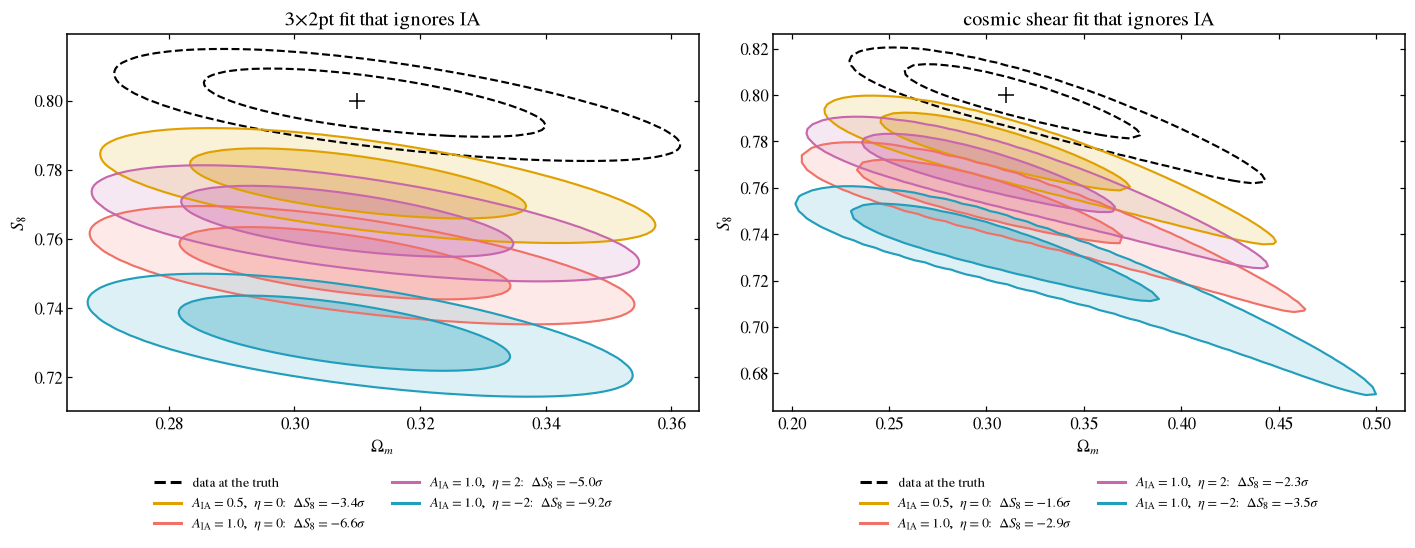

In [19]:
IA_CASES = {(0.5, 0): GOLD, (1.0, 0): CORAL, (1.0, 2): MAGENTA, (1.0, -2): BLUE}     # (A_IA, eta_IA): colour
DD_IA = {(A, eta): data_vector({'A_IA': A, 'eta_IA': eta}) - D_FID for A, eta in IA_CASES}

fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
for ax, name in zip(axes, ['3×2pt', 'cosmic shear']):
    fits = {case: posterior(make_mask(COMBOS[name]), dd) for case, dd in DD_IA.items()}
    entries = [(R, IA_CASES[(A, eta)], rf'$A_{{\rm IA}}={A},\ \eta={eta}$:  $\Delta S_8 = {shift_in_sigma(R):+.1f}\sigma$')
               for (A, eta), R in fits.items()]
    tools.plot_posteriors(ax, entries, THETA0_3, reference=POST[name], legend='below', pad=0.05,
                          title=f'{name} fit that ignores IA')
plt.tight_layout(); plt.show()

**Baryons.** AGN feedback pushes gas out of haloes and suppresses $P(k)$ on small scales (slides 010–011). Our
data use the parametric dip; the dashed line is the Chisari et al. (2018) hydro-simulation fit at $z=0$, for
scale.

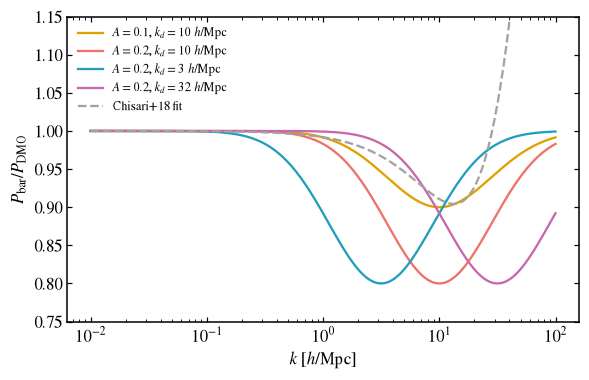

In [20]:
k = np.geomspace(1e-2, 1e2, 300)                     # h/Mpc
chisari18 = (1 + (k / 28.5) ** 2) / (1 + (k / 28.5) ** 1.39)

fig, ax = plt.subplots(figsize=(6, 3.6))
for (A, logk), col in zip([(0.1, 1.0), (0.2, 1.0), (0.2, 0.5), (0.2, 1.5)], [GOLD, CORAL, BLUE, MAGENTA]):
    ax.plot(k, baryon_suppression(k, A, logk), color=col, label=rf'$A = {A}$, $k_d = {10**logk:.0f}\ h$/Mpc')
ax.plot(k, chisari18, '--', color=GRAY, label='Chisari+18 fit')
ax.set(xscale='log', ylim=(0.75, 1.15), xlabel=r'$k$ [$h$/Mpc]', ylabel=r'$P_{\rm bar}/P_{\rm DMO}$')
ax.legend(fontsize=8); plt.show()

Where in $k$ does a dip hurt? Move a dip of depth $A = 0.2$ across $k$ and record the $S_8$ shift. Cosmic shear
on small angles is most sensitive, especially $\xi_-$, which weights high $\ell$.

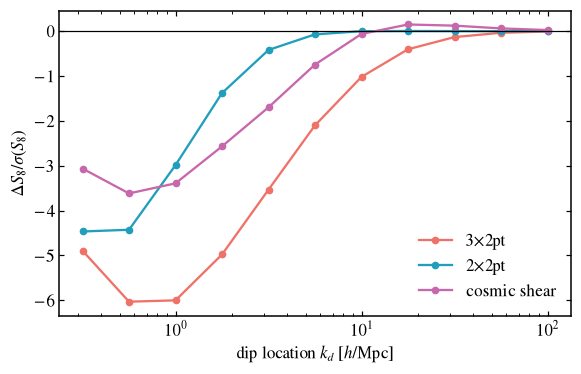

In [21]:
LOGKD = np.linspace(-0.5, 2.0, 11)
DD_BAR = {lk: data_vector({'A_bar': 0.2, 'logk_bar': lk}) - D_FID for lk in LOGKD}

fig, ax = plt.subplots(figsize=(6, 3.6))
for name in ['3×2pt', '2×2pt', 'cosmic shear']:
    mask = make_mask(COMBOS[name])
    ax.plot(10 ** LOGKD, [shift_in_sigma(posterior(mask, DD_BAR[lk])) for lk in LOGKD], 'o-', ms=4,
            color=COLOR[name], label=name)
ax.axhline(0, color='k', lw=0.8)
ax.set(xscale='log', xlabel=r'dip location $k_d$ [$h$/Mpc]', ylabel=r'$\Delta S_8/\sigma(S_8)$'); ax.legend(); plt.show()

The fix most analyses use is a **scale cut**: drop small-angle $\xi_\pm$. That removes bias but also information.

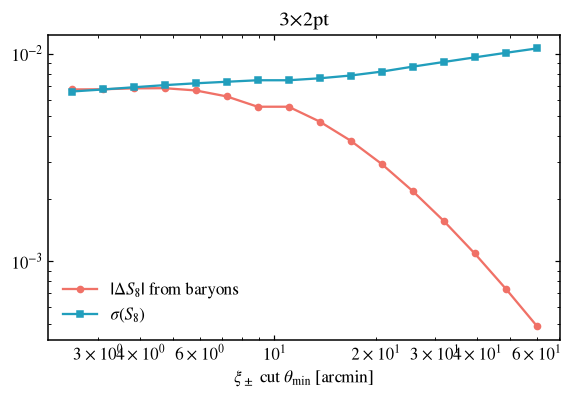

In [22]:
dd = DD_BAR[LOGKD[6]]                                # A = 0.2 at k_d = 10 h/Mpc
cuts = np.geomspace(2.5, 60, 16)                     # theta_min for xi+- [arcmin]
fits = [posterior(make_mask(theta_xi=t), dd) for t in cuts]

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(cuts, [abs(R['map'][1] - S8_TRUE) for R in fits], 'o-', ms=4, color=CORAL, label=r'$|\Delta S_8|$ from baryons')
ax.plot(cuts, [R['sd'][1] for R in fits], 's-', ms=4, color=BLUE, label=r'$\sigma(S_8)$')
ax.set(xscale='log', yscale='log', xlabel=r'$\xi_\pm$ cut $\theta_{\rm min}$ [arcmin]', title='3×2pt')
ax.legend(); plt.show()

Cutting small scales makes the bias fall much faster than the error grows. A cut is "safe" once the bias is well
below $\sigma$ (typically $< 0.3\sigma$). The alternative is to *model* baryons with free parameters and
marginalise over them.

---
### Things to try

1. In part 2, rescale the covariance (`COV / 4` is a survey with 4× the area, `COV * 4` one with ¼). How much
   less banana-shaped does cosmic shear become as the data improve?
2. In part 3, find the $|\Delta z_s|$ that gives a $1\sigma$ $S_8$ bias for cosmic shear alone and for 3×2pt.
   Which is more robust, and why?
3. In part 4, move the baryon dip to $k_d = 1\,h$/Mpc and redo the scale-cut plot. Is there still a safe cut?
4. In `bias_explorer.html`, find two systematics whose $S_8$ shifts cancel. Does the $\chi^2$ notice?